# 02. 순차 실행 Graph
## 학습 목표
- `START`, `END`, `add_node`, `add_edge`, `compile`로 실행 순서를 정의한다.
- `invoke()`의 최종 State와 `stream(..., stream_mode="updates")`의 Node별 변경분을 구분한다.

**핵심 개념**: 고정 Edge는 개발자가 정한 순서대로 Node를 실행한다. API 키는 필요하지 않다.

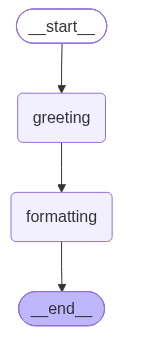

## 실행 전 예측
입력 `{"name": "지수", "message": ""}`가 `greeting → formatting`을 지나면 `message`는 어떤 문자열이 될까?  
두 Node 중 어느 쪽이 `name`을 변경할까?  

In [ ]:
from typing import TypedDict
from langgraph.graph import START, END, StateGraph

# State Schema 정의
class GreetingState(TypedDict):
    name: str
    message: str

# Node 정의
def greeting(state: GreetingState) -> dict:
    
    print("실행 Node: greeting")

    return {"message": f"안녕하세요, {state['name']}님"}

# Node 정의
def formatting(state: GreetingState) -> dict:
    print("실행 Node: formatting")
    
    return {"message": f"[인사] {state['message']}!"}

# StateGraph builder 객체 생성
builder = StateGraph(GreetingState)

# Node를 Graph에 등록
builder.add_node("greeting", greeting)
builder.add_node("formatting", formatting)

# Edge 연결
builder.add_edge(START, "greeting")
builder.add_edge("greeting", "formatting")
builder.add_edge("formatting", END)

# Graph 컴파일
graph = builder.compile()

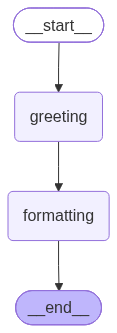

In [3]:
from IPython.display import Image, display

# PNG 생성에 네트워크 등이 필요하면 Mermaid 텍스트로 대체한다.
try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as exc:
    print("PNG 시각화 불가:", type(exc).__name__)
    print(graph.get_graph().draw_mermaid())

In [ ]:
start_state = {"name": "지수", "message": ""}
final_state = graph.invoke(start_state)

print("invoke 최종 State:", final_state)
assert final_state == {"name": "지수", "message": "[인사] 안녕하세요, 지수님!"}

실행 Node: greeting
실행 Node: formatting
invoke 최종 State: {'name': '지수', 'message': '[인사] 안녕하세요, 지수님!'}


In [5]:
# 별도의 새 실행이다. invoke와 stream이 각각 Graph를 한 번씩 실행한다.
for update in graph.stream(start_state, stream_mode="updates"):
    print("Node별 업데이트:", update)

실행 Node: greeting
Node별 업데이트: {'greeting': {'message': '안녕하세요, 지수님'}}
실행 Node: formatting
Node별 업데이트: {'formatting': {'message': '[인사] 안녕하세요, 지수님!'}}


`greeting`이 만든 `message`를 `formatting`이 읽는다.   
State는 Node 사이에 공유되지만 `stream_mode="updates"`에는 전체 State 대신 해당 Node의 변경분이 나타난다.

## 문제해결


## 이해 확인
1. `formatting`에서 `state["name"]`을 읽을 수 있는 이유는 무엇인가?  
   **해설:** 앞 Node가 `name`을 반환하지 않아도 기존 State에 남아 있기 때문이다.
2. `invoke()`와 `stream(..., stream_mode="updates")`의 출력 차이는 무엇인가?  
   **해설:** 전자는 최종 State, 후자는 Node별 변경분을 제공한다.

**핵심 정리:** 순차 Edge가 실행 순서를 고정하고, 각 Node는 같은 State의 최신 값을 읽는다.